# OCR and Multimodal Nutrition Extraction Workflow

This companion notebook covers the supervised-data preparation and extraction portion of the assignment. It loads the refreshed enriched Open Food Facts sample, reviews country/serving/image coverage, creates leakage-aware candidate splits, demonstrates OCR and rule-based entity tagging, specifies image-grounded annotation requirements, and gives opt-in LayoutLMv3 training/inference instructions.

## Important constraints

- Product-level nutrition metadata is **weak supervision only**; it does not prove that values are visible in a linked image. This notebook never treats it as gold OCR labels.
- It does not bulk-download images or model weights. OCR inference is opt-in and limited to one manually selected nutrition-panel image.
- LayoutLMv3 training is CPU-expensive and cannot be meaningfully run until a set of OCR words, boxes, and BIO tags has been manually verified. The notebook provides a small-dataset smoke-test path, not a trained result.
- All scores remain unreported unless manually verified gold transcriptions and structured records exist.

## Workflow

1. Load enriched sample / inspect image and serving metadata.
2. Select candidates for human image review; annotate and adjudicate.
3. Create product-group splits only after annotation.
4. Run OCR baseline + spatial entity/value extraction.
5. Optionally train LayoutLMv3 and compare against OCR on the exact same held-out set.
6. Record failures, metrics, costs, and limitations.

In [2]:
# 1. Environment, seed, configuration, and sample loading
from __future__ import annotations

import importlib.util
import importlib.metadata as metadata
import json
import logging
import random
import re
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from PIL import Image

ROOT = Path.cwd()
if not (ROOT / "src" / "nutrition_extraction").exists() and (ROOT / "nutrition_extraction_solution" / "src").exists():
    ROOT = ROOT / "nutrition_extraction_solution"
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
CONFIG = yaml.safe_load((ROOT / "configs" / "base.yaml").read_text(encoding="utf-8"))
SEED = int(CONFIG["training"]["seed"])
random.seed(SEED)
np.random.seed(SEED)
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
LOGGER = logging.getLogger("nutrition_extraction_workflow")

DATA_PATH = ROOT / "data" / "openfoodfacts_eda_enriched.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Enriched sample missing: {DATA_PATH}. Run nutrition-acquire first.")
df = pd.read_csv(DATA_PATH, low_memory=False)
print("Rows / columns:", df.shape)
print("Python:", sys.version.split()[0], "| pandas:", metadata.version("pandas"), "| numpy:", metadata.version("numpy"))
print("Torch installed:", importlib.util.find_spec("torch") is not None)
print("Dataset:", DATA_PATH)
display(pd.DataFrame({"column": df.columns.astype(str), "dtype": df.dtypes.astype(str)}))

Rows / columns: (50000, 44)
Python: 3.12.10 | pandas: 2.3.3 | numpy: 2.5.4
Torch installed: True
Dataset: c:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\data\openfoodfacts_eda_enriched.csv


,column,dtype
code,code,int64
product_name,product_name,object
generic_name,generic_name,object
quantity,quantity,object
brands,brands,object
categories,categories,object
countries,countries,object
ingredients_text,ingredients_text,object
serving_size,serving_size,object
last_image_t,last_image_t,float64


In [4]:
# 2. Dataset-level candidate coverage, serving context, image review queue
from nutrition_extraction.eda import analyze_export

summary, missingness, coverage = analyze_export(df)
def present(series: pd.Series) -> pd.Series:
    normalized = series.astype("string").str.strip().str.casefold()
    return series.notna() & ~normalized.isin({"", "undefined", "nan", "none", "null", "n/a", "na"})

image_url_cols = [c for c in df.columns if str(c).lower().startswith("image_") and str(c).lower().endswith("_url")]
nutrition_url_cols = [c for c in image_url_cols if "nutrition" in str(c).lower()]
any_image = pd.concat([present(df[c]) for c in image_url_cols], axis=1).any(axis=1) if image_url_cols else pd.Series(False, index=df.index)
nutrition_image = pd.concat([present(df[c]) for c in nutrition_url_cols], axis=1).any(axis=1) if nutrition_url_cols else pd.Series(False, index=df.index)
target_fields = [c for c in ["energy-kcal_100g", "fat_100g", "saturated-fat_100g", "carbohydrates_100g", "sugars_100g", "fiber_100g", "proteins_100g", "salt_100g", "sodium_100g"] if c in df]
target_present = pd.concat([pd.to_numeric(df[c], errors="coerce").notna() for c in target_fields], axis=1).any(axis=1) if target_fields else pd.Series(False, index=df.index)
candidate = any_image & target_present
strict_candidate = nutrition_image & target_present
serving_columns = [c for c in ["quantity", "serving_size", "serving_quantity", "nutrition_data_per", "countries"] if c in df]
serving_summary = {c: {"non_missing": int(present(df[c]).sum()), "fraction": float(present(df[c]).mean()), "examples": df.loc[present(df[c]), c].astype(str).head(5).tolist()} for c in serving_columns}
print({
    "rows": len(df), "image_url_columns": image_url_cols,
    "rows_any_image_url": int(any_image.sum()), "rows_nutrition_image_url": int(nutrition_image.sum()),
    "rows_any_image_plus_target_metadata": int(candidate.sum()),
    "rows_nutrition_image_plus_target_metadata": int(strict_candidate.sum()),
    "manual_image_label_verification_done": False,
})
print("Serving / locale coverage:")
print(json.dumps(serving_summary, indent=2, ensure_ascii=False))

# Review queue is capped to 500 records and contains references only; it does not fetch image files.
review_columns = [c for c in ["code", "product_name", "brands", "categories", "countries", "quantity", "serving_size", "serving_quantity", "nutrition_data_per", *nutrition_url_cols, *target_fields] if c in df]
review_queue = df.loc[strict_candidate, review_columns].head(500).copy()
review_output = ROOT / "reports" / "eda" / "enriched_manual_review_candidates.csv"
review_output.parent.mkdir(parents=True, exist_ok=True)
review_queue.to_csv(review_output, index=False)
print(f"Saved {len(review_queue)} candidate references to {review_output}")

{'rows': 50000, 'image_url_columns': ['image_url', 'image_small_url', 'image_ingredients_url', 'image_ingredients_small_url', 'image_nutrition_url', 'image_nutrition_small_url'], 'rows_any_image_url': 13694, 'rows_nutrition_image_url': 8803, 'rows_any_image_plus_target_metadata': 12771, 'rows_nutrition_image_plus_target_metadata': 8527, 'manual_image_label_verification_done': False}
Serving / locale coverage:
{
  "quantity": {
    "non_missing": 32493,
    "fraction": 0.64986,
    "examples": [
      "350 g",
      "1 g",
      "1.5 g",
      "1.5 g",
      "30 g"
    ]
  },
  "serving_size": {
    "non_missing": 47600,
    "fraction": 0.952,
    "examples": [
      "1g",
      "1.61 ONZ (45 g)",
      "1.5g",
      "1.5 g",
      "1.5g"
    ]
  },
  "countries": {
    "non_missing": 42799,
    "fraction": 0.85598,
    "examples": [
      "United States",
      "United States",
      "United States",
      "United States",
      "United States"
    ]
  }
}
Saved 500 candidate reference

In [12]:
# Enriched-sample descriptive coverage, duplicates, country distribution, and numeric quality
from nutrition_extraction.eda import nutrition_statistics

eda_summary, missingness, coverage = analyze_export(df)
nutrition_cols = coverage["field"].tolist() if not coverage.empty else []
nutrition_stats = nutrition_statistics(df, nutrition_cols)
quality = {
    "unique_product_codes": int(df["code"].nunique(dropna=True)) if "code" in df else None,
    "duplicate_code_rows": int(df["code"].duplicated(keep=False).sum()) if "code" in df else None,
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "blank_product_names": int((~present(df["product_name"])).sum()) if "product_name" in df else None,
    "rows_with_any_structured_nutrition": eda_summary.get("rows_with_any_structured_nutrition"),
    "rows_any_image_url": int(any_image.sum()),
    "rows_nutrition_image_url": int(nutrition_image.sum()),
    "candidate_rows_any_image_plus_target": int(candidate.sum()),
    "strict_candidate_rows_nutrition_image_plus_target": int(strict_candidate.sum()),
}
print("Enriched sample quality summary:")
print(json.dumps(quality, indent=2))
print("Selected target coverage:")
display(coverage[coverage["field"].isin(target_fields)])
print("Selected target numeric statistics:")
display(nutrition_stats[nutrition_stats["field"].isin(target_fields)])
if "countries" in df:
    country_values = df["countries"].dropna().astype("string").str.split(",").explode().str.strip()
    country_values = country_values[~country_values.str.casefold().isin({"", "undefined", "nan", "none", "null", "n/a", "na"})]
    country_counts = country_values.value_counts()
    print("Top countries (split comma-separated labels; occurrences, not unique products):")
    display(country_counts.head(15).rename_axis("country").reset_index(name="product_field_occurrences"))
macro_fields = [c for c in ["fat_100g", "carbohydrates_100g", "proteins_100g"] if c in df]
macro_values = df[macro_fields].apply(pd.to_numeric, errors="coerce")
macro_sum = macro_values.sum(axis=1, min_count=1)
print("Macro subtotal diagnostics (exploratory only; not a validity verdict):", {
    "all_three_nonmissing_rows": int(macro_values.notna().all(axis=1).sum()),
    "rows_macro_subtotal_over_100": int((macro_sum > 100).sum()),
    "rows_macro_subtotal_over_110": int((macro_sum > 110).sum()),
})

Enriched sample quality summary:
{
  "unique_product_codes": 50000,
  "duplicate_code_rows": 0,
  "exact_duplicate_rows": 0,
  "blank_product_names": 261,
  "rows_with_any_structured_nutrition": 47775,
  "rows_any_image_url": 13694,
  "rows_nutrition_image_url": 8803,
  "candidate_rows_any_image_plus_target": 12771,
  "strict_candidate_rows_nutrition_image_plus_target": 8527
}
Selected target coverage:


,field,non_missing_count,coverage_fraction
1,energy-kcal_100g,47748,0.95496
3,fat_100g,47704,0.95408
7,carbohydrates_100g,47687,0.95374
10,proteins_100g,47685,0.95370
11,salt_100g,47293,0.94586
12,sodium_100g,47293,0.94586
8,sugars_100g,45681,0.91362
4,saturated-fat_100g,42428,0.84856
9,fiber_100g,39535,0.79070


Selected target numeric statistics:


,field,valid_numeric_count,mean,std,min,p01,median,p99,max,negative_count,iqr_outlier_count
1,energy-kcal_100g,47748,577.997612,973.414784,0.0,0.0,321.000000,5515.300000,47000.0,0,5653
2,fat_100g,47704,50.897294,4579.051485,0.0,0.0,4.080000,561.000000,1000000.0,0,6108
3,carbohydrates_100g,47687,67.613127,217.557469,0.0,0.0,25.500000,625.000000,40000.0,0,4938
4,proteins_100g,47685,13.131889,34.099017,-12.6,0.0,4.580000,113.389565,1430.0,1,4236
5,salt_100g,47293,1.089041,29.458680,0.0,0.0,0.006670,10.000000,4980.0,0,5633
6,sodium_100g,47293,0.465276,12.503303,0.0,0.0,0.002890,4.062160,1990.0,0,5388
7,sugars_100g,45681,33.576293,203.629166,0.0,0.0,7.030000,408.000000,40000.0,0,5214
8,saturated-fat_100g,42428,10.392806,29.672661,0.0,0.0,1.220000,102.000000,1200.0,0,4625
9,fiber_100g,39535,5.220936,16.637416,-44.7,0.0,1.321911,50.700000,900.0,1,5173


Top countries (split comma-separated labels; occurrences, not unique products):


,country,product_field_occurrences
0,United States,41212
1,France,958
2,World,473
3,United Kingdom,211
4,États-Unis,109
5,Royaume-Uni,101
6,Estados Unidos,54
7,Canada,46
8,Germany,34
9,Deutschland,27


Macro subtotal diagnostics (exploratory only; not a validity verdict): {'all_three_nonmissing_rows': 47599, 'rows_macro_subtotal_over_100': 11909, 'rows_macro_subtotal_over_110': 11517}


In [5]:
# Save enriched-sample coverage, country frequency, serving completeness, and metadata candidate counts.
ENRICHED_REPORT = ROOT / "reports" / "eda"
ENRICHED_REPORT.mkdir(parents=True, exist_ok=True)
summary_out = dict(summary)
summary_out.update({
    "rows_with_any_image_url": int(any_image.sum()),
    "rows_with_nutrition_image_url": int(nutrition_image.sum()),
    "rows_with_image_and_target_metadata": int(candidate.sum()),
    "rows_with_nutrition_image_and_target_metadata": int(strict_candidate.sum()),
    "serving_locale_coverage": serving_summary,
    "annotation_verified_pairs": 0,
    "warning": "Metadata pairing is a review candidate only; image-label alignment is not visually verified.",
})
(ENRICHED_REPORT / "enriched_summary.json").write_text(json.dumps(summary_out, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
if "countries" in df:
    country_counts = df["countries"].dropna().astype("string").str.split(",").explode().str.strip()
    country_counts = country_counts[~country_counts.str.casefold().isin({"", "undefined", "nan", "none", "null", "n/a", "na"})]
    country_counts.value_counts().rename_axis("country").reset_index(name="count").to_csv(ENRICHED_REPORT / "country_counts.csv", index=False)
if not coverage.empty:
    coverage.to_csv(ENRICHED_REPORT / "enriched_nutrition_coverage.csv", index=False)
print("Saved enriched EDA summary and country/coverage outputs in", ENRICHED_REPORT)

Saved enriched EDA summary and country/coverage outputs in c:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\reports\eda




## Annotation scout: find a manageable review batch

This scout ranks records with nutrition-image URLs and available structured targets to help choose images for **manual visual review**. It favors more complete target metadata and product/locale/serving context, but its score is only a queue ordering—not confidence and not verified image-label alignment. Outputs include a ranked candidate inventory with fields for reviewer status and notes. Confirm the panel image and every field manually; keep an `alignment_verified` flag false until done.

In [26]:
# Deterministically rank annotation-review candidates and export a locale-diverse pilot.
import importlib
import nutrition_extraction.annotation_scout as scout_module
scout_module = importlib.reload(scout_module)
from nutrition_extraction.annotation_scout import build_annotation_candidates, build_diverse_review_batch

verified_gold_path = ROOT / "data" / "evaluation" / "gold_records.jsonl"
verified_product_ids = {
    str(json.loads(line)["product_id"])
    for line in verified_gold_path.read_text(encoding="utf-8").splitlines()
    if line.strip()
} if verified_gold_path.exists() else set()
scout_candidates, scout_summary = build_annotation_candidates(df, verified_product_ids=verified_product_ids)
SCOUT_DIR = ROOT / "reports" / "annotation_scout"
SCOUT_DIR.mkdir(parents=True, exist_ok=True)
(SCOUT_DIR / "summary.json").write_text(json.dumps(scout_summary, indent=2, ensure_ascii=False), encoding="utf-8")
scout_queue_path = SCOUT_DIR / "annotation_review_queue.csv"
scout_candidates.head(500).to_csv(scout_queue_path, index=False)
pilot = build_diverse_review_batch(scout_candidates, size=100, per_locale=3)
pilot_path = SCOUT_DIR / "annotation_pilot_batch.csv"
pilot.to_csv(pilot_path, index=False)
print(json.dumps(scout_summary, indent=2, ensure_ascii=False))
print("Full top-ranked review queue:", scout_queue_path)
print("Locale-diverse pilot batch:", pilot_path)
display(pilot[["pilot_order", "review_rank", "code", "product_name", "countries", "serving_size", "nutrition_image_locale_hint", "target_field_count", "target_fields_present", "annotation_priority_score", "review_status", "alignment_verified", "nutrition_image_url"]].head(20))

{
  "input_rows": 50000,
  "input_columns": 44,
  "nutrition_image_url_candidates": 8803,
  "ranked_candidates_with_any_target": 8527,
  "target_fields_scored": [
    "energy-kcal_100g",
    "fat_100g",
    "saturated-fat_100g",
    "carbohydrates_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
    "sodium_100g"
  ],
  "candidate_count_by_target_support": {
    "at_least_1_of_9_targets": 8527,
    "at_least_3_of_9_targets": 8520,
    "at_least_5_of_9_targets": 8484,
    "at_least_7_of_9_targets": 8294,
    "at_least_9_of_9_targets": 6550
  },
  "candidate_locale_hints": {
    "en": 7426,
    "fr": 907,
    "es": 101,
    "de": 24,
    "it": 21,
    "nl": 7,
    "ar": 7,
    "fi": 5,
    "ro": 4,
    "pt": 4,
    "da": 4,
    "la": 3,
    "eu": 2,
    "sv": 2,
    "ru": 1,
    "lt": 1,
    "uk": 1,
    "ca": 1,
    "zh": 1,
    "cs": 1,
    "th": 1,
    "sr": 1,
    "no": 1,
    "ja": 1
  },
  "record_level_alignment_verified_count": 1,
  "token_level_a

,pilot_order,review_rank,code,product_name,countries,serving_size,nutrition_image_locale_hint,target_field_count,target_fields_present,annotation_priority_score,review_status,alignment_verified,nutrition_image_url
0,1,1,9034,Pitted Prunes,United States,1.5 oz. (40 g),en,9,"energy-kcal_100g,fat_100g,saturated-fat_100g,c...",1.35,pending_manual_visual_review,False,https://images.openfoodfacts.org/images/produc...
1,2,2,10894,Diced In Tomato Juice,United States,130g,en,9,"energy-kcal_100g,fat_100g,saturated-fat_100g,c...",1.35,pending_manual_visual_review,False,https://images.openfoodfacts.org/images/produc...
2,3,3,14649,Extra Virgin Olive Oil,United States,1 portion (175 g),en,9,"energy-kcal_100g,fat_100g,saturated-fat_100g,c...",1.35,pending_manual_visual_review,False,https://images.openfoodfacts.org/images/produc...
14,4,15,99165,Cracked Black Pepper & Salted Popped Potato Chips,"France, Royaume-Uni",23 g,fr,9,"energy-kcal_100g,fat_100g,saturated-fat_100g,c...",1.35,pending_manual_visual_review,False,https://images.openfoodfacts.org/images/produc...
26,5,27,159241,Risotto Aux Crevettes,France,350 g,fr,9,"energy-kcal_100g,fat_100g,saturated-fat_100g,c...",1.35,pending_manual_visual_review,False,https://images.openfoodfacts.org/images/produc...
35,6,36,200615,Garlic Doughballs,France,6 Doughballs (90 g),fr,9,"energy-kcal_100g,fat_100g,saturated-fat_100g,c...",1.35,pending_manual_visual_review,False,https://images.openfoodfacts.org/images/produc...
169,7,170,11110190291,Fuego Colby Jack,United States,1 slice (22 g),es,9,"energy-kcal_100g,fat_100g,saturated-fat_100g,c...",1.35,pending_manual_visual_review,False,https://images.openfoodfacts.org/images/produc...
505,8,506,13602004369,Jarabe sabor fresa,México,40 g,es,9,"energy-kcal_100g,fat_100g,saturated-fat_100g,c...",1.35,pending_manual_visual_review,False,https://images.openfoodfacts.org/images/produc...
506,9,507,13602004383,Jarabe sabor vainilla,Mexico,40 g,es,9,"energy-kcal_100g,fat_100g,saturated-fat_100g,c...",1.35,pending_manual_visual_review,False,https://images.openfoodfacts.org/images/produc...
397,10,398,11152225623,Carbonated Soft Drink,United States,1 BOTTLE (200 ml),de,9,"energy-kcal_100g,fat_100g,saturated-fat_100g,c...",1.35,pending_manual_visual_review,False,https://images.openfoodfacts.org/images/produc...


## 3. Image-grounded annotation contract and human review

For each selected nutrition-panel image, create a JSONL annotation with aligned OCR words, 0–1000 bounding boxes, BIO tags, and verified structured record. Reviewers must confirm image/product identity, whether each field is visible, the applicable locale and nutrition basis, and any uncertainty. Double-review a subset and adjudicate disagreements. Do not copy the product-level metadata into tags without visual verification.

Example row format (illustrative schema only; values below are not an Open Food Facts observation):

```json
{"product_id":"your-reviewed-product","image_path":"data/images/product_nutrition.jpg","words":["Energy","200","kcal","Fat","8","g"],"boxes":[[20,30,160,70],[170,30,230,70],[235,30,300,70],[20,90,90,130],[170,90,200,130],[205,90,235,130]],"tags":["B-NUTRIENT","B-VALUE","B-UNIT","B-NUTRIENT","B-VALUE","B-UNIT"],"gold_record":{"fields":[{"nutrient":"energy","value":200,"unit":"kcal","basis":"100g"},{"nutrient":"fat","value":8,"unit":"g","basis":"100g"}]}}
```

Keep `annotations.jsonl` and images local/ignored by Git if licensing or privacy requires. Split by `product_id` only after annotation; consider brand/country holdouts for generalization analysis.

In [6]:
# 4. Deterministic group split of manually annotated manifest only
from nutrition_extraction.splitting import read_jsonl, make_splits

ANNOTATION_PATH = ROOT / CONFIG["data"]["annotation_manifest"]
SPLITS_DIR = ROOT / CONFIG["data"]["splits_dir"]
if ANNOTATION_PATH.exists():
    annotations = read_jsonl(ANNOTATION_PATH)
    split_cfg = CONFIG["split"]
    splits = make_splits(
        annotations,
        group_key=split_cfg["group_key"],
        train_fraction=split_cfg["train_fraction"],
        validation_fraction=split_cfg["validation_fraction"],
        test_fraction=split_cfg["test_fraction"],
        seed=split_cfg["seed"],
    )
    SPLITS_DIR.mkdir(parents=True, exist_ok=True)
    for name, records in splits.items():
        with (SPLITS_DIR / f"{name}.jsonl").open("w", encoding="utf-8") as stream:
            for record in records:
                stream.write(json.dumps(record, ensure_ascii=False) + "\n")
    print({name: len(records) for name, records in splits.items()})
else:
    print(f"No manually verified annotations found at {ANNOTATION_PATH}; refusing to create false supervised splits.")
    print("The earlier metadata-only candidate split is exploratory and must not be used as a model benchmark.")

No manually verified annotations found at c:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\data\annotations.jsonl; refusing to create false supervised splits.
The earlier metadata-only candidate split is exploratory and must not be used as a model benchmark.


## 5. OCR baseline: EasyOCR (CPU), with alternatives

EasyOCR is installed in the project virtual environment and is the configured baseline; the adapter returns text, bounding boxes, and confidence values. For this reviewed image, use the French language code `fr` and CPU mode. EasyOCR itself is installed, but its detector/recognizer model weights are not yet downloaded. First use requires internet access and downloads those weights; the notebook and config keep that off until explicitly approved. Tesseract remains an alternative but requires its native executable. PaddleOCR is another optional backend with a separate Windows CPU runtime.

In [ ]:
# Configure EasyOCR for the visually verified local French panel. Model downloads require explicit opt-in.
from nutrition_extraction.ocr import EasyOCRBackend, PaddleOCRBackend, TesseractBackend, load_preprocessed_image
from nutrition_extraction.extraction import tag_ocr_tokens, associate_rows, extract_record
from nutrition_extraction.evaluation import measure_latency
import shutil

print("EasyOCR package installed:", importlib.util.find_spec("easyocr") is not None)
print("Tesseract executable:", shutil.which("tesseract"))
print("PaddleOCR installed:", importlib.util.find_spec("paddleocr") is not None)
RUN_OCR = False
OCR_BACKEND = CONFIG.get("ocr", {}).get("backend", "easyocr")
OCR_IMAGE = ROOT / "data" / "manual_samples" / "241013128_nutrition.jpg"
if RUN_OCR:
    if not OCR_IMAGE.exists():
        raise FileNotFoundError(f"Manually reviewed panel image not found: {OCR_IMAGE}")
    if OCR_BACKEND == "easyocr":
        if not CONFIG.get("ocr", {}).get("allow_model_downloads", False):
            raise RuntimeError("EasyOCR weights are not cached. Approve the model download, then set ocr.allow_model_downloads=true in configs/base.yaml.")
        backend = EasyOCRBackend(
            languages=CONFIG.get("ocr", {}).get("easyocr_languages", ["fr"]),
            gpu=False,
            download_enabled=True,
            model_storage_directory=str(ROOT / CONFIG.get("ocr", {}).get("model_storage_directory", "models/easyocr")),
        )
    elif OCR_BACKEND == "paddleocr":
        backend = PaddleOCRBackend(language=CONFIG.get("ocr", {}).get("paddle_language", "fr"))
    elif OCR_BACKEND == "tesseract":
        backend = TesseractBackend(CONFIG.get("ocr", {}).get("tesseract_cmd"), language="fra")
    else:
        raise ValueError(f"Unsupported OCR backend: {OCR_BACKEND}")
    image = load_preprocessed_image(OCR_IMAGE, int(CONFIG.get("ocr", {}).get("max_image_side", 2000)))
    tokens, elapsed_s = measure_latency(backend.extract, image)
    record = extract_record(OCR_IMAGE.stem, tokens, str(OCR_IMAGE), float(CONFIG.get("ocr", {}).get("confidence_threshold", .70)))
    print(f"OCR tokens={len(tokens)} elapsed_seconds={elapsed_s:.3f}")
    display(pd.DataFrame([token.__dict__ for token in tokens]))
    display(pd.DataFrame(tag_ocr_tokens(tokens)))
    display(record.to_dict())
else:
    print("OCR not run. EasyOCR is installed; its model weights are still gated to avoid an unapproved download.")
    print("After approving weights, enable ocr.allow_model_downloads and set RUN_OCR=True to process the reviewed French panel.")

Tesseract executable: None
PaddleOCR installed: False
OCR not run. Set RUN_OCR=True after installing a backend and adding one local panel image.
No OCR accuracy claim is made until OCR output is compared with a manually verified transcription.


## 6. Entity tagging, value normalization, and row association

The rule baseline tags known nutrient aliases, numeric values and units, and serving-basis phrases; it groups words by visual row and horizontal position. This is intentionally a transparent baseline, not a learned entity classifier. Row association is heuristic and should flag multiple values, missing units, multiple nutrients on a row, low OCR confidence, and ambiguous bases for human review. Add locale-specific nutrient aliases and explicit conversion policies only after documenting the annotation conventions.

In [11]:
# Rule baseline smoke test using synthetic tokens only (not model/OCR performance data).
import importlib
import nutrition_extraction.extraction as extraction_module
extraction_module = importlib.reload(extraction_module)
from nutrition_extraction.ocr import OCRToken
from nutrition_extraction.extraction import extract_record, tag_ocr_tokens
from nutrition_extraction.schema import NutritionRecord

synthetic_tokens = [
    OCRToken("Energy", (20, 20, 110, 50), .99),
    OCRToken("200", (180, 20, 220, 50), .98),
    OCRToken("kcal", (225, 20, 270, 50), .97),
    OCRToken("Fat", (20, 80, 70, 110), .96),
    OCRToken("8", (180, 80, 195, 110), .95),
    OCRToken("g", (200, 80, 215, 110), .94),
]
print("Synthetic OCR tokens:")
display(pd.DataFrame([token.__dict__ for token in synthetic_tokens]))
print("Tags:")
display(pd.DataFrame(tag_ocr_tokens(synthetic_tokens)))
synthetic_result = extract_record("synthetic-demo", synthetic_tokens, "synthetic-only", confidence_threshold=.7)
print("Synthetic demonstration only; not a measured result.")
print(json.dumps(synthetic_result.to_dict(), indent=2))
assert [field.nutrient for field in synthetic_result.fields] == ["energy", "fat"]
assert [field.unit for field in synthetic_result.fields] == ["kcal", "g"]

Synthetic OCR tokens:


,text,box,confidence
0,Energy,"(20, 20, 110, 50)",0.99
1,200,"(180, 20, 220, 50)",0.98
2,kcal,"(225, 20, 270, 50)",0.97
3,Fat,"(20, 80, 70, 110)",0.96
4,8,"(180, 80, 195, 110)",0.95
5,g,"(200, 80, 215, 110)",0.94


Tags:


,text,box,confidence,entity_type,normalized
0,Energy,"(20, 20, 110, 50)",0.99,NUTRIENT,{'nutrient': 'energy'}
1,200,"(180, 20, 220, 50)",0.98,VALUE,"{'value': 200.0, 'unit': None}"
2,kcal,"(225, 20, 270, 50)",0.97,UNIT,{'unit': 'kcal'}
3,Fat,"(20, 80, 70, 110)",0.96,NUTRIENT,{'nutrient': 'fat'}
4,8,"(180, 80, 195, 110)",0.95,VALUE,"{'value': 8.0, 'unit': None}"
5,g,"(200, 80, 215, 110)",0.94,UNIT,{'unit': 'g'}


Synthetic demonstration only; not a measured result.
{
  "product_id": "synthetic-demo",
  "fields": [
    {
      "nutrient": "energy",
      "value": 200.0,
      "unit": "kcal",
      "basis": null,
      "raw_text": "Energy 200 kcal",
      "confidence": 0.97
    },
    {
      "nutrient": "fat",
      "value": 8.0,
      "unit": "g",
      "basis": null,
      "raw_text": "Fat 8 g",
      "confidence": 0.94
    }
  ],
  "source_image": "synthetic-only",
  "needs_review": false,
  "warnings": [],
  "schema_version": "1.0"
}


## 7. LayoutLMv3 trainable document extraction

**Model design:** Input is the nutrition-panel image plus OCR words, word boxes normalized to `[0,1000]`, and manually verified BIO tags (`NUTRIENT`, `VALUE`, `UNIT`, `SERVING`). The LayoutLMv3 token-classification head predicts a label per token; cross-entropy ignores special/padded tokens (`-100`). Training uses AdamW, fixed seed, validation-loss checkpoint selection, and product-group train/validation/test splits. This representation combines text, image, and layout. The test split stays untouched until final evaluation.

**CPU/weights:** No pretrained model download is initiated in this notebook. `microsoft/layoutlmv3-base` weights are sizeable and CPU fine-tuning is slow. Only enable the next cell after reviewing local RAM/disk, model license, and approval to download. Without manually annotated manifests, there is nothing valid to train on.

In [17]:
# Explicit opt-in only: set True after review, verified annotation, and split creation.
ALLOW_MODEL_WEIGHT_DOWNLOAD = False
RUN_TRAINING = False
if RUN_TRAINING:
    if not ALLOW_MODEL_WEIGHT_DOWNLOAD:
        raise RuntimeError("Set ALLOW_MODEL_WEIGHT_DOWNLOAD=True only after approving model download and disk/RAM use.")
    if not ANNOTATION_PATH.exists():
        raise FileNotFoundError("Create manually verified data/annotations.jsonl before training.")
    if not all((SPLITS_DIR / f"{name}.jsonl").exists() for name in ("train", "validation", "test")):
        raise FileNotFoundError("Create verified group-aware train/validation/test splits before training.")
    raise NotImplementedError("Training is available as the package CLI; run nutrition-train --config configs/base.yaml after reviewing resources.")
else:
    print("LayoutLMv3 training skipped: no model weights downloaded; no verified annotation labels currently available.")
    print("When ready, use: nutrition-train --config configs/base.yaml")

LayoutLMv3 training skipped: no model weights downloaded; no verified annotation labels currently available.
When ready, use: nutrition-train --config configs/base.yaml


# Example one-image inference entrypoints; no weights or images are downloaded in this cell.
OCR_COMMAND = "nutrition-ocr-predict --config configs/base.yaml --image data/manual_samples/panel.jpg --output reports/prediction.json --ocr-backend tesseract"
LAYOUT_MODEL_COMMAND = "nutrition-predict --config configs/base.yaml --checkpoint artifacts/model --image data/manual_samples/panel.jpg --output reports/layoutlm_prediction.json"
print("OCR baseline:", OCR_COMMAND)
print("Trained LayoutLMv3:", LAYOUT_MODEL_COMMAND)
print("Evaluation CLI:", "nutrition-evaluate --config configs/base.yaml --checkpoint artifacts/model")
print("Evaluation metrics available:", ["CER", "WER", "entity precision/recall/F1", "field exact match", "record exact match", "numeric MAE", "unit accuracy", "basis accuracy", "latency"])
print("Model weight download remains off; commands require approved model weights and manually annotated train data.")

In [18]:
# Example one-image inference entrypoints; no weights or images are downloaded in this cell.
OCR_COMMAND = "nutrition-ocr-predict --config configs/base.yaml --image data/manual_samples/panel.jpg --output reports/prediction.json --ocr-backend tesseract"
LAYOUT_MODEL_COMMAND = "nutrition-predict --config configs/base.yaml --checkpoint artifacts/model --image data/manual_samples/panel.jpg --output reports/layoutlm_prediction.json"
print("OCR baseline:", OCR_COMMAND)
print("Trained LayoutLMv3:", LAYOUT_MODEL_COMMAND)
print("Structured result schema:", json.dumps(NUTRITION_RECORD_JSON_SCHEMA if "NUTRITION_RECORD_JSON_SCHEMA" in globals() else {
    "product_id": "string", "source_image": "string|null", "fields": [{"nutrient": "string", "value": "number|null", "unit": "string|null", "basis": "string|null", "raw_text": "string|null", "confidence": "number|null"}], "needs_review": "boolean", "warnings": ["string"], "schema_version": "string"
}, indent=2))

OCR baseline: nutrition-ocr-predict --config configs/base.yaml --image data/manual_samples/panel.jpg --output reports/prediction.json --ocr-backend tesseract
Trained LayoutLMv3: nutrition-predict --config configs/base.yaml --checkpoint artifacts/model --image data/manual_samples/panel.jpg --output reports/layoutlm_prediction.json
Structured result schema: {
  "product_id": "string",
  "source_image": "string|null",
  "fields": [
    {
      "nutrient": "string",
      "value": "number|null",
      "unit": "string|null",
      "basis": "string|null",
      "raw_text": "string|null",
      "confidence": "number|null"
    }
  ],
  "needs_review": "boolean",
  "warnings": [
    "string"
  ],
  "schema_version": "string"
}


## 9. Metrics and failure analysis

Use the same frozen, manually verified test records for OCR+rules and LayoutLMv3. Keep OCR recognition errors separate from entity/tagging and row-association errors. Report supports and definitions with each metric; specify numeric tolerance and unit/basis conversions before scoring. Failure categories should include: character confusions/decimal point errors, missed or hallucinated nutrient names, BIO boundary mistakes, wrong row/column pairing, serving-vs-100g ambiguity, wrong unit conversion, wrong product/image alignment, illegible/rotated/curved panels, and low-confidence abstentions.

In [21]:
# Metrics smoke-test only; values here are deliberately synthetic, not model results.
from nutrition_extraction.evaluation import character_error_rate, word_error_rate, entity_prf, structured_metrics, measure_latency
from nutrition_extraction.schema import NutritionField, NutritionRecord

synthetic_gold_text = "energy 200 kcal fat 8 g"
synthetic_hyp_text = "energy 200 kcal fat 8 g"
print("Synthetic CER/WER examples (not measured):", character_error_rate(synthetic_gold_text, synthetic_hyp_text), word_error_rate(synthetic_gold_text, synthetic_hyp_text))
print("Synthetic entity PRF (not measured):", entity_prf([("NUTRIENT", 0, 1)], [("NUTRIENT", 0, 1)]))
sample_gold = NutritionRecord("demo", [NutritionField("protein", 4.0, "g", "100g")])
sample_pred = NutritionRecord("demo", [NutritionField("protein", 3.8, "g", "100g")])
print("Synthetic structured-metric example only:", structured_metrics([sample_gold], [sample_pred]))

GOLD_RECORDS = ROOT / "data" / "evaluation" / "gold_records.jsonl"
PRED_RECORDS = ROOT / "data" / "evaluation" / "predicted_records.jsonl"
GOLD_OCR = ROOT / "data" / "evaluation" / "gold_ocr.txt"
PRED_OCR = ROOT / "data" / "evaluation" / "predicted_ocr.txt"
if all(path.exists() for path in [GOLD_RECORDS, PRED_RECORDS]):
    gold = [NutritionRecord.from_dict(json.loads(line)) for line in GOLD_RECORDS.read_text(encoding="utf-8").splitlines() if line.strip()]
    pred = [NutritionRecord.from_dict(json.loads(line)) for line in PRED_RECORDS.read_text(encoding="utf-8").splitlines() if line.strip()]
    print("Real manually verified structured metrics:", structured_metrics(gold, pred))
elif all(path.exists() for path in [GOLD_OCR, PRED_OCR]):
    reference, hypothesis = GOLD_OCR.read_text(encoding="utf-8"), PRED_OCR.read_text(encoding="utf-8")
    print("Real manually transcribed OCR CER/WER:", character_error_rate(reference, hypothesis), word_error_rate(reference, hypothesis))
elif GOLD_RECORDS.exists() or GOLD_OCR.exists():
    print("Manual gold reference exists, but no matching model/OCR prediction exists yet; no real score is reported.")
else:
    print("No manually verified gold reference is available; no real score is reported.")

ERROR_LOG = ROOT / "reports" / "eda" / "error_analysis_template.csv"
if not ERROR_LOG.exists():
    ERROR_LOG.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame(columns=["product_id", "image_path", "failure_type", "gold", "prediction", "root_cause", "severity", "action"]).to_csv(ERROR_LOG, index=False)
print("Error analysis log:", ERROR_LOG)

Synthetic CER/WER examples (not measured): 0.0 0.0
Synthetic entity PRF (not measured): {'true_positive': 1, 'predicted': 1, 'gold': 1, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0}
Synthetic structured-metric example only: {'record_count': 1, 'field_support': 1, 'field_exact_match_accuracy': 0.0, 'record_exact_match_accuracy': 0.0, 'numeric_mae': 0.20000000000000018, 'numeric_mae_support': 1, 'unit_accuracy': 1.0, 'unit_support': 1, 'basis_accuracy': 1.0, 'basis_support': 1}
Manual gold reference exists, but no matching model/OCR prediction exists yet; no real score is reported.
Error analysis log: c:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\reports\eda\error_analysis_template.csv


## 10. Comparison: OCR baseline vs document model vs VLM

| Approach | Advantages | Main costs/risks | Recommended role |
|---|---|---|---|
| PaddleOCR/Tesseract + rules | CPU-friendly, transparent, fast to prototype | OCR errors, hand-maintained aliases, fragile table association | First baseline and diagnostic component |
| LayoutLMv3 token tagging | Uses word text, spatial layout, and image together; BIO tagging is auditable | Requires verified token/box labels; weight download, RAM, CPU fine-tuning time | Compare only after annotation set exists |
| Open-weight vision-language model | Can reason over visual context and potentially output structured fields | Model size/CPU latency, hallucination, JSON reliability, license and resource costs | Optional research comparison, only with approval |

Compare all approaches on the same held-out annotated products. Include latency and abstention, not only extraction F1. Do not send images to paid APIs; optional API/VLM evaluation is out of current scope.



## 11. One human-verified image transcription

I visually inspected the Open Food Facts nutrition-panel image for product code `241013128` (Eclairs, French label). The panel visibly contains both per-100-g and 90-g serving columns. The structured values below are manually transcribed from the image and compared with the sample metadata; this is one verified record, not a representative benchmark. Transcription was manual—not produced by OCR. This is record-level gold, not yet word-level OCR boxes/BIO labels, so it is suitable for validating structured-record serialization and a future OCR comparison, but not enough to train LayoutLMv3 or report meaningful aggregate metrics.


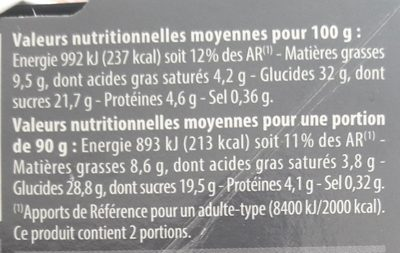

Visually inspected image dimensions: (400, 253)
Saved one manually transcribed OCR reference and structured record: c:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\data\evaluation
Fields: 16 | image was visually checked: yes | OCR engine produced this text: no


In [13]:
# Store one manually verified transcription and structured gold record from the inspected OFF image.
# The downloaded file is one image only, capped at 8 MiB. No OCR engine/model is invoked here.
import urllib.request
from PIL import Image

VERIFIED_PRODUCT_ID = "241013128"
VERIFIED_IMAGE_URL = "https://images.openfoodfacts.org/images/products/000/024/101/3128/nutrition_fr.10.400.jpg"
MANUAL_IMAGE_DIR = ROOT / "data" / "manual_samples"
MANUAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
VERIFIED_IMAGE_PATH = MANUAL_IMAGE_DIR / f"{VERIFIED_PRODUCT_ID}_nutrition.jpg"
if not VERIFIED_IMAGE_PATH.exists():
    request = urllib.request.Request(VERIFIED_IMAGE_URL, headers={"User-Agent": "NutritionExtractionResearch/0.1"})
    with urllib.request.urlopen(request, timeout=20) as response:
        image_bytes = response.read(8 * 1024 * 1024 + 1)
    if len(image_bytes) > 8 * 1024 * 1024:
        raise ValueError("Image exceeds 8 MiB manual-review safety cap")
    VERIFIED_IMAGE_PATH.write_bytes(image_bytes)
with Image.open(VERIFIED_IMAGE_PATH) as verified_image:
    verified_image.verify()
with Image.open(VERIFIED_IMAGE_PATH) as verified_image:
    display(verified_image.convert("RGB"))
    print("Visually inspected image dimensions:", verified_image.size)

manual_transcription = (
    "Valeurs nutritionnelles moyennes pour 100 g : Energie 992 kJ (237 kcal) soit 12% des AR(1) - "
    "Matières grasses 9,5 g, dont acides gras saturés 4,2 g - Glucides 32 g, dont sucres 21,7 g - "
    "Protéines 4,6 g - Sel 0,36 g.\n"
    "Valeurs nutritionnelles moyennes pour une portion de 90 g : Energie 893 kJ (213 kcal) soit 11% des AR(1) - "
    "Matières grasses 8,6 g, dont acides gras saturés 3,8 g - Glucides 28,8 g, dont sucres 19,5 g - "
    "Protéines 4,1 g - Sel 0,32 g.\n"
    "(1) Apports de Référence pour un adulte-type (8400 kJ/2000 kcal). Ce produit contient 2 portions."
)
fields = []
for basis, values in {
    "100g": [("energy", 992, "kJ"), ("energy", 237, "kcal"), ("fat", 9.5, "g"), ("saturated_fat", 4.2, "g"),
             ("carbohydrates", 32.0, "g"), ("sugars", 21.7, "g"), ("proteins", 4.6, "g"), ("salt", 0.36, "g")],
    "serving_90g": [("energy", 893, "kJ"), ("energy", 213, "kcal"), ("fat", 8.6, "g"), ("saturated_fat", 3.8, "g"),
                    ("carbohydrates", 28.8, "g"), ("sugars", 19.5, "g"), ("proteins", 4.1, "g"), ("salt", 0.32, "g")],
}.items():
    for nutrient, value, unit in values:
        fields.append({"nutrient": nutrient, "value": value, "unit": unit, "basis": basis,
                       "raw_text": None, "confidence": None})
manual_gold = {
    "product_id": VERIFIED_PRODUCT_ID,
    "source_image": str(VERIFIED_IMAGE_PATH.relative_to(ROOT)).replace("\\", "/"),
    "source_image_url": VERIFIED_IMAGE_URL,
    "fields": fields,
    "needs_review": True,
    "warnings": ["One visual manual transcription; word-level OCR boxes and BIO tags not annotated; do not treat as training corpus."],
    "schema_version": "1.0",
    "annotation_method": "manual_visual_transcription",
    "reviewed_date": "2026-10-28",
}
EVAL_DIR = ROOT / "data" / "evaluation"
EVAL_DIR.mkdir(parents=True, exist_ok=True)
(EVAL_DIR / "gold_ocr.txt").write_text(manual_transcription, encoding="utf-8")
(EVAL_DIR / "gold_records.jsonl").write_text(json.dumps(manual_gold, ensure_ascii=False) + "\n", encoding="utf-8")
from nutrition_extraction.schema import NutritionRecord
round_trip = NutritionRecord.from_dict(manual_gold)
assert len(round_trip.fields) == 16
print("Saved and schema-validated one manually transcribed OCR reference and structured record:", EVAL_DIR)
print("Fields:", len(fields), "| image visually checked: yes | OCR engine produced this text: no")

In [14]:
# Audit note for the single visually reviewed image/value match.
manual_review_note = pd.DataFrame([{
    "product_id": VERIFIED_PRODUCT_ID,
    "image_path": manual_gold["source_image"],
    "image_is_nutrition_panel": True,
    "table_basis_seen": "per 100 g and per 90 g portion",
    "metadata_comparison": "Visible per-100-g values agree with the Open Food Facts structured fields for this product in the sample.",
    "review_status": "one image manually inspected; row-level fields transcribed",
    "token_boxes_bio_tags": "not annotated",
    "evidence_limit": "single example only; not a model-quality estimate",
}])
manual_review_note.to_csv(ENRICHED_REPORT / "manual_verification_log.csv", index=False)
display(manual_review_note)

,product_id,image_path,image_is_nutrition_panel,table_basis_seen,metadata_comparison,review_status,token_boxes_bio_tags,evidence_limit
0,241013128,data/manual_samples/241013128_nutrition.jpg,True,per 100 g and per 90 g portion,Visible per-100-g values agree with the Open F...,one image manually inspected; row-level fields...,not annotated,single example only; not a model-quality estimate


## 12. Automated checks

The tests exercise the data/profile utilities, leakage-safe splits, unit/value parsing, entity metrics, and JSON round-tripping. They do not measure model quality. Run them in the project virtual environment; the trained-model tests are intentionally absent because no pretrained weights or token-labeled corpus is available.

In [25]:
# Run project tests from this notebook kernel.
import subprocess
completed = subprocess.run([sys.executable, "-m", "pytest", "-q", str(ROOT / "tests")], cwd=ROOT, capture_output=True, text=True)
print(completed.stdout)
if completed.returncode != 0:
    print(completed.stderr)
    raise RuntimeError(f"pytest exited with {completed.returncode}")

..............                                                           [100%]
14 passed in 3.00s



In [15]:
# Repair the enriched cache if another EDA notebook cell narrowed it in-place; this notebook's `df` was loaded before that change.
ENRICHED_PATH = ROOT / "data" / "openfoodfacts_eda_enriched.csv"
if "countries" in df.columns and "serving_size" in df.columns and len(df) == 50_000:
    df.to_csv(ENRICHED_PATH, index=False)
    print("Restored enriched 50k sample cache:", ENRICHED_PATH, "columns:", len(df.columns))
else:
    print("Enriched dataframe not available in memory; reacquire the sample before restoring the cache.")

Restored enriched 50k sample cache: c:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\data\openfoodfacts_eda_enriched.csv columns: 44
